# Cumulative Wave Power — Survey Date Analysis

**Author:** Chelsea Volpano
**Email:** cvolpano@contractor.usgs.gov | cvolpano@gmail.com
**Date:** 2026-06-24; updated 2026-11-03
**Created using Claude Sonnet 4.6; updated with Claude Opus 5.5**

---

Standalone notebook — loads all data from scratch.
Computes cumulative wave power (kWh/m) forward and backward from each survey
date using NDBC 44013, with thresholds at 200, 400, and 600 kWh/m.

**Time.** All times are **UTC**: NDBC reports UTC only (https://www.ndbc.noaa.gov/faq/measdes.shtml) and
`waveDataDownloader.ipynb` does not convert them. Survey dates are taken as 00:00 UTC.

**Method.** Wave power per unit crest length, $P = \rho g^2 H_s^2 T / (64\pi)$ (kW/m), with `DPD` as the period.
Cumulative energy is the time integral of $P$ (trapezoid rule) at the buoy's **own sampling times**, and each
threshold crossing time is interpolated between the two samples either side of it.

### Change log
| Date | Change |
|---|---|
| 2026-06-24 | First version (hourly means, cumulative sum). |
| 2026-11-03 | Native buoy sampling instead of hourly means: energy integrated over the actual time between samples; crossing times interpolated to the minute (were rounded to the start of an hour); gaps up to `MAX_GAP_H` bridged, longer ones counted as zero power and reported (before, every empty hour silently counted as zero); new columns `gap_h` and `n_samples` in the threshold CSV. |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

%matplotlib inline

In [3]:
# ── Configuration ─────────────────────────────────────────────────────────────
OUT_DIR  = Path("C:\\Users\\cvolp\\PUVprocessing_usgs\\nanopod\\data\\wave_data")
PLOT_DIR = Path("C:\\Users\\cvolp\\PUVprocessing_usgs\\nanopod\\data\\wave_plots")
PLOT_DIR.mkdir(exist_ok=True)

START = "2024-10-01"
END   = "2025-03-31"

NDBC_44013_FILE = OUT_DIR / f"NDBC_44013_{START[:7]}_to_{END[:7]}.csv"
GRAIN_FILE      = OUT_DIR / "caco-waves_grainsize.csv"   # update path as needed

SURVEY_DATES     = ["2024-10-23", "2025-01-23", "2025-02-19", "2025-03-06"]
LOOKBACK_DAYS    = 21
LOOKFWD_DAYS     = 21
POWER_THRESHOLDS = [200, 400, 600]   # kWh/m
MAX_GAP_H        = 3.0   # bridge gaps up to this long (h); longer = no power counted

# Physical constants
RHO   = 1025.0    # seawater density (kg/m³)

G       = 9.81      # gravitational acceleration (m/s²)
P_CONST = (RHO * G**2) / (64 * np.pi) / 1000  # wave power constant → kW/m

# Spectral colormap
_sp = plt.colormaps["RdYlBu"]
PALETTE = {
    "ndbc":    _sp(0.95),
    "wis":     _sp(0.08),
    "survey":  _sp(0.55),
    "insitu":  _sp(0.72),
}
THRESHOLD_COLORS = [_sp(0.95), _sp(0.75), _sp(0.08)]

## 1. Load NDBC 44013 & Compute Wave Power
**Native sampling.** The NDBC file also holds rows with only meteorological data (every 10 min), where the wave
columns are 99.00 (missing). Those rows are dropped, so what remains are the actual wave measurements. The cell prints
how often they occur.

**Cumulative energy, `E_kWh_m`.** Energy between two samples is the trapezoid
$\tfrac12 (P_{i-1} + P_i)\,\Delta t_i$, with $\Delta t$ in hours, so kW/m × h = kWh/m. A running sum (`np.cumsum`) of those
pieces gives the energy since the start of the record; energy between any two times is then just a difference of two
values. The old version averaged to hourly bins and summed them, which assumes every value lasts exactly 1 h and counts
every empty hour as zero power.

**Gaps.** A gap up to `MAX_GAP_H` is bridged by the trapezoid (power assumed to change linearly). A longer gap contributes
no energy, as before, but it is now recorded in `gap_before_h` so the totals can say how much time was missing.

**Coding note.** Every step here works on whole columns (`diff`, `shift`, `np.where`, `cumsum`), so even a full year of
10-min records takes milliseconds.

In [4]:
EPOCH = pd.Timestamp("1970-01-01")


def to_hours(index):
    """Datetime index -> float hours since 1970 (any time resolution)."""
    return ((index - EPOCH) / pd.Timedelta("1h")).to_numpy(dtype=float)


def load_ndbc_csv(path):
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    df.index.name = "datetime"  # UTC
    df = df.rename(columns={"WVHT": "Hs", "DPD": "Tp"})
    df = df.apply(pd.to_numeric, errors="coerce")
    df["Hs"] = df["Hs"].where(df["Hs"] < 99.0)
    df["Tp"] = df["Tp"].where(df["Tp"] < 99.0)
    df["P_kW_m"] = P_CONST * df["Hs"]**2 * df["Tp"]
    return df


ndbc_44013 = load_ndbc_csv(NDBC_44013_FILE)
# Keep only rows with a wave measurement, in time order, no repeated times.
ndbc_44013 = (ndbc_44013.dropna(subset=["P_kW_m"]).sort_index()
              .loc[lambda d: ~d.index.duplicated()])

hours = to_hours(ndbc_44013.index)
dt_h = np.diff(hours, prepend=np.nan)       # hours since the previous sample
p = ndbc_44013["P_kW_m"].to_numpy()
bridged = dt_h <= MAX_GAP_H                 # False for the first row and long gaps
piece = np.where(bridged, 0.5 * (p + np.roll(p, 1)) * dt_h, 0.0)
ndbc_44013["E_kWh_m"] = np.cumsum(piece)    # energy since the first sample
ndbc_44013["gap_before_h"] = np.where(bridged | np.isnan(dt_h), 0.0, dt_h)

step = pd.Series(np.round(dt_h[1:] * 60)).value_counts()
print(f"NDBC 44013 wave samples: {len(ndbc_44013)}  "
      f"({ndbc_44013.index.min()} → {ndbc_44013.index.max()} UTC)")
print("Most common sampling intervals (min): "
      + ", ".join(f"{m:.0f} ({n})" for m, n in step.head(4).items()))
long_gaps = ndbc_44013.loc[ndbc_44013["gap_before_h"] > 0, "gap_before_h"]
print(f"Gaps longer than {MAX_GAP_H} h: {len(long_gaps)}, "
      f"{long_gaps.sum():.0f} h in total (no power counted)")
ndbc_44013[["Hs", "Tp", "P_kW_m"]].describe().round(3)

NDBC 44013 wave samples: 8515  (2024-10-01 00:10:00 → 2025-03-31 23:40:00 UTC)
Most common sampling intervals (min): 30 (8384), 60 (107), 90 (10), 120 (5)
Gaps longer than 3.0 h: 5, 34 h in total (no power counted)


,Hs,Tp,P_kW_m
count,8515.000,8515.000,8515.000
mean,0.997,6.387,4.185
std,0.510,3.103,5.693
min,0.250,2.060,0.068
25%,0.620,3.700,0.927
50%,0.890,5.260,2.050
75%,1.250,9.090,5.163
max,3.620,17.390,49.440


## 2. Compute Cumulative Wave Power Forward & Backward from Survey Dates
`cumulative_around` takes the energy at the survey time by interpolating `E_kWh_m`, then the cumulative power at each
sample is the difference from it: `E - E_survey` going forward, `E_survey - E` going backward.

`crossings` finds when each threshold is first reached. `np.searchsorted` finds, for all thresholds at once, the first
sample at or above the threshold; the crossing time is then interpolated linearly between that sample and the one before
it. Because cumulative power never decreases, this is the exact time at which the trapezoid sum reaches the threshold.

In [5]:
def cumulative_around(df, survey_date, lookback_days, lookfwd_days):
    """
    Cumulative wave power (kWh/m) forward and backward from a survey date.
    Both segments start at cum_power=0 at the survey time.
    x axis is days from survey date (negative = before, positive = after).
    """
    t_survey = pd.Timestamp(survey_date)
    t0 = t_survey - pd.Timedelta(days=lookback_days)
    t1 = t_survey + pd.Timedelta(days=lookfwd_days)

    window = df.loc[t0:t1]
    if window.empty:
        return None, None
    e_survey = np.interp(to_hours(pd.DatetimeIndex([t_survey]))[0],
                         to_hours(df.index), df["E_kWh_m"].to_numpy())

    # Backward: newest first, so index 0 is nearest the survey
    backward = window.loc[:t_survey].iloc[::-1].copy()
    backward["cum_power"] = e_survey - backward["E_kWh_m"]
    backward["days"] = -((t_survey - backward.index).total_seconds() / 86400)

    forward = window.loc[t_survey:].copy()
    forward["cum_power"] = forward["E_kWh_m"] - e_survey
    forward["days"] = (forward.index - t_survey).total_seconds() / 86400

    return backward, forward


def crossings(df_seg, t_survey, thresholds=POWER_THRESHOLDS):
    """Interpolated time each threshold is first reached in one segment.

    Returns a DataFrame indexed by threshold with datetime_crossed, days
    (signed, as on the plot) and days_to_threshold (absolute); NaT/NaN if
    the threshold is not reached in the segment.
    """
    cum = df_seg["cum_power"].to_numpy()
    hrs = to_hours(df_seg.index)
    thr = np.asarray(thresholds, dtype=float)
    k = np.searchsorted(cum, thr, side="left")       # first sample >= thr
    found = k < cum.size
    k = np.clip(k, 1, max(cum.size - 1, 1))
    c0, c1 = cum[k - 1], cum[k]
    frac = np.where(c1 > c0, (thr - c0) / np.where(c1 > c0, c1 - c0, 1), 1.0)
    frac = np.clip(frac, 0, 1)
    h = hrs[k - 1] + frac * (hrs[k] - hrs[k - 1])
    # Threshold already reached at the first sample (survey is inside it)
    h = np.where(cum[0] >= thr, hrs[0], h)
    t_cross = (EPOCH + pd.to_timedelta(h, unit="h")).round("min")
    out = pd.DataFrame({"datetime_crossed": t_cross}, index=thr.astype(int))
    out.index.name = "threshold_kWh_m"
    out.loc[~found, "datetime_crossed"] = pd.NaT
    out["days"] = (out["datetime_crossed"] - t_survey).dt.total_seconds() / 86400
    out["days_to_threshold"] = out["days"].abs()
    return out

## 3. Plot — Cumulative Wave Power by Survey Date

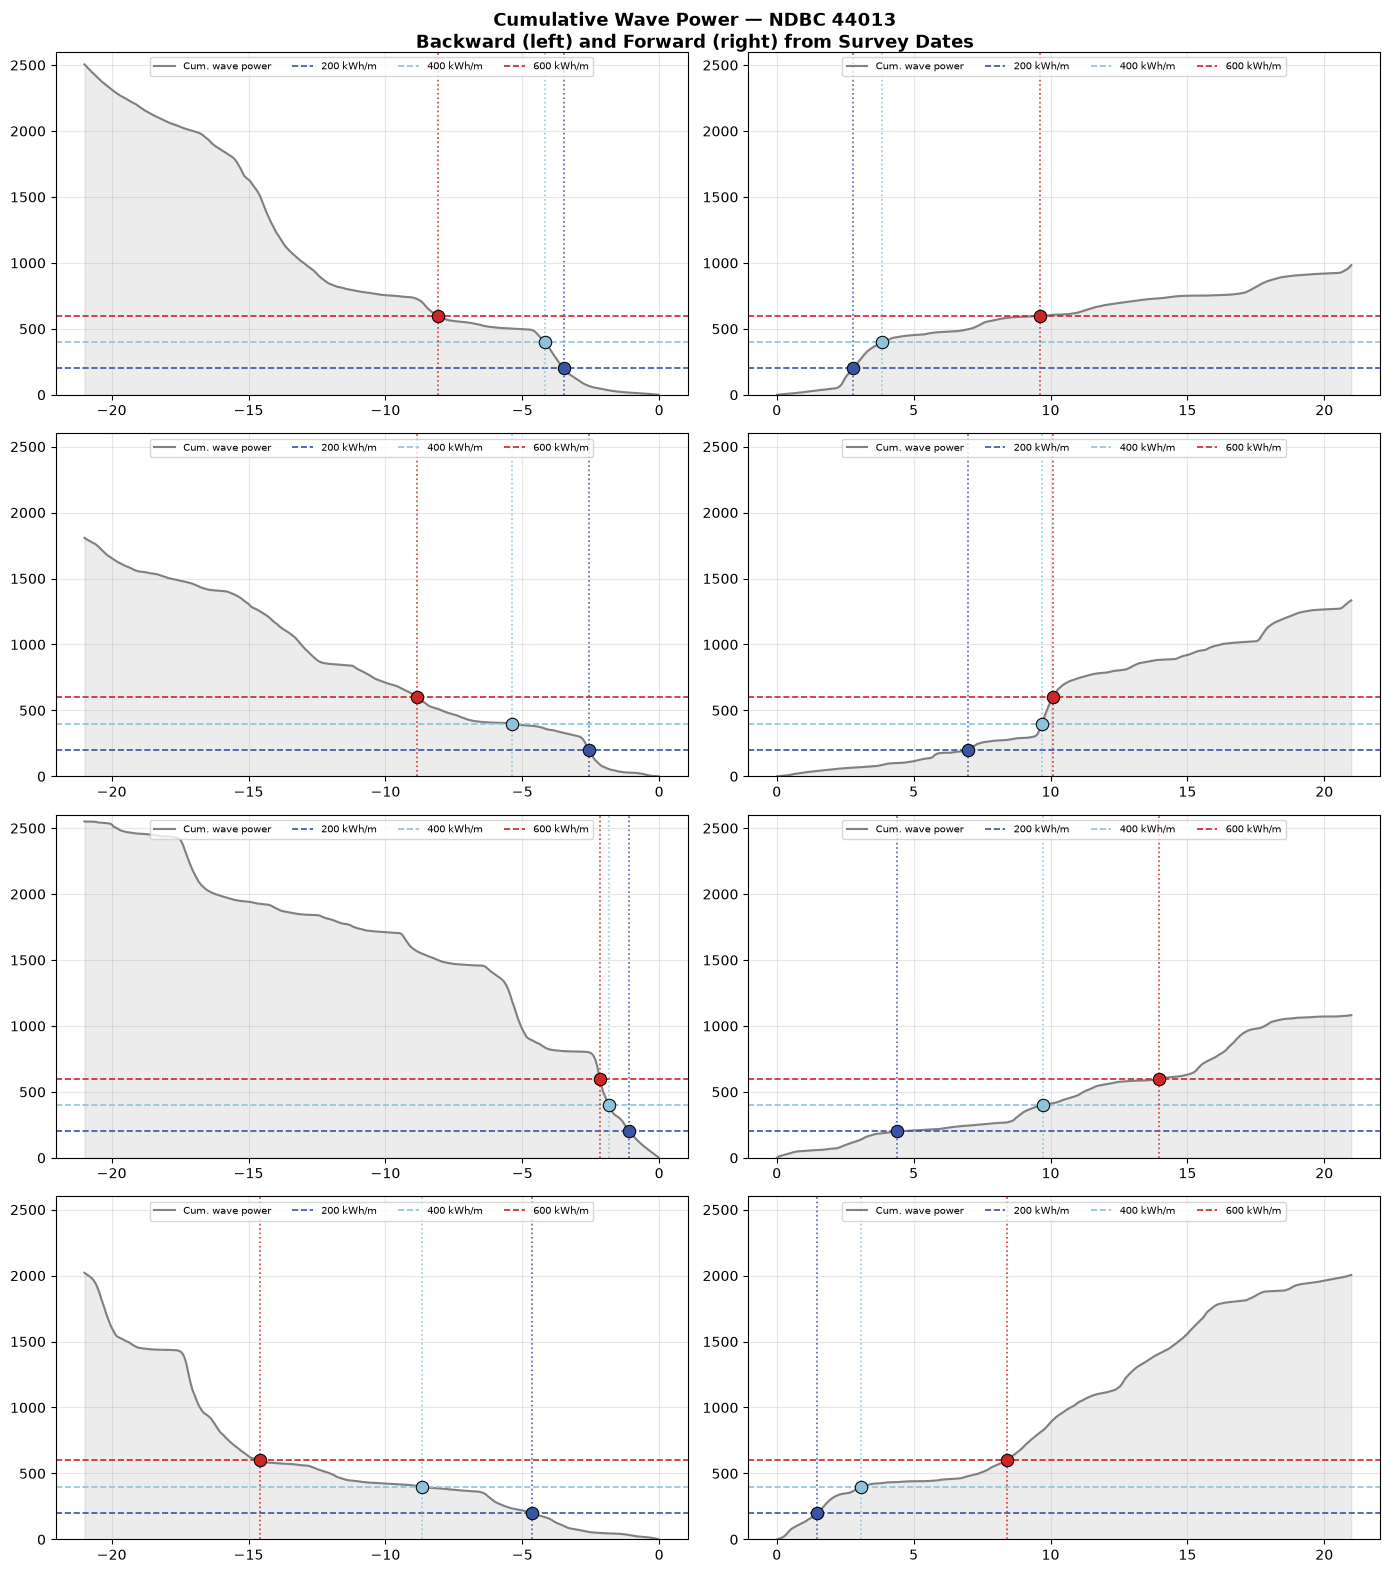

✓ Saved cumulative_wave_power_surveys.png


In [6]:
# Compute global y-axis limits across all surveys and directions
all_cum_power = []
for survey_date in SURVEY_DATES:
    bk, fw = cumulative_around(ndbc_44013, survey_date, LOOKBACK_DAYS, LOOKFWD_DAYS)
    for seg in [bk, fw]:
        if seg is not None:
            all_cum_power.append(seg["cum_power"].max())
ymax_power = max(all_cum_power) * 1.05


n_surveys = len(SURVEY_DATES)
fig, axes = plt.subplots(n_surveys, 2, figsize=(14, 4 * n_surveys))
fig.suptitle(
    "Cumulative Wave Power — NDBC 44013\n"
    "Backward (left) and Forward (right) from Survey Dates",
    fontsize=13, fontweight="bold"
)

for i, survey_date in enumerate(SURVEY_DATES):
    backward, forward = cumulative_around(
        ndbc_44013, survey_date, LOOKBACK_DAYS, LOOKFWD_DAYS)
    if backward is None:
        print(f"  ⚠ No data around {survey_date}")
        continue

    t_survey = pd.Timestamp(survey_date)

    for j, (seg_label, df_seg, xlabel) in enumerate([
        (f"← {LOOKBACK_DAYS} days before survey", backward, "Days before survey"),
        (f"{LOOKFWD_DAYS} days after survey →",   forward,  "Days after survey"),
    ]):
        ax  = axes[i, j]
        ax.set_ylim([0,2600])

        x = df_seg["days"]

        # ── Cumulative wave power ─────────────────────────────────────────────
        ax.fill_between(x, df_seg["cum_power"], alpha=0.15, color="gray")
        ax.plot(x, df_seg["cum_power"], color="gray", lw=1.5,
                label="Cum. wave power")

        # Threshold lines and interpolated crossing markers
        cross = crossings(df_seg, t_survey)
        for thresh, tcol in zip(POWER_THRESHOLDS, THRESHOLD_COLORS):
            ax.axhline(thresh, color=tcol, lw=1.2, ls="--", label=f"{thresh} kWh/m")
            x_cross = cross.loc[thresh, "days"]
            if np.isfinite(x_cross):
                ax.axvline(x_cross, color=tcol, lw=1.2, ls=":", alpha=0.9)
                ax.scatter(x_cross, thresh, color=tcol, s=80, zorder=5,linewidth=0.75, edgecolor="black")


        # Combined legend
        lines1, labels1 = ax.get_legend_handles_labels()
        ax.grid(True,zorder=0, alpha=0.3)
        ax.legend(lines1, labels1,
                  fontsize=7.5, loc="upper center", ncol=5)

fig.tight_layout()
fig.savefig(PLOT_DIR / "cumulative_wave_power_surveys.png", bbox_inches="tight", dpi=350)
plt.show()
print("✓ Saved cumulative_wave_power_surveys.png")

## 4. Summary Table — Days to Reach Each Power Threshold

In [7]:
print(f"{'Survey':<15} {'Direction':<10} "
      + "".join(f"{'Days to '+str(t)+' kWh/m':>20}" for t in POWER_THRESHOLDS))
print("-" * (25 + 20 * len(POWER_THRESHOLDS)))

for survey_date in SURVEY_DATES:
    backward, forward = cumulative_around(
        ndbc_44013, survey_date, LOOKBACK_DAYS, LOOKFWD_DAYS)
    if backward is None:
        continue
    t_survey = pd.Timestamp(survey_date)

    for seg_label, df_seg in [("backward", backward), ("forward", forward)]:
        days = crossings(df_seg, t_survey)["days_to_threshold"]
        row_str = f"  {t_survey.strftime('%Y-%m-%d'):<13} {seg_label:<10}"
        row_str += "".join(f"  {d:>18.2f}d" if np.isfinite(d)
                           else f"  {'> '+str(LOOKBACK_DAYS)+'d':>18}"
                           for d in days)
        print(row_str)

Survey          Direction     Days to 200 kWh/m   Days to 400 kWh/m   Days to 600 kWh/m
-------------------------------------------------------------------------------------
  2024-10-23    backward                  3.47d                4.18d                8.07d
  2024-10-23    forward                   2.77d                3.85d                9.63d
  2025-01-23    backward                  2.57d                5.37d                8.83d
  2025-01-23    forward                   6.99d                9.68d               10.08d
  2025-02-19    backward                  1.10d                1.85d                2.17d
  2025-02-19    forward                   4.41d                9.73d               13.96d
  2025-03-06    backward                  4.65d                8.67d               14.58d
  2025-03-06    forward                   1.47d                3.07d                8.40d


## 5. Save threshold crossing summary to CSV

In [8]:
# One row per survey × direction × threshold combination.
# Columns: survey_date, direction, threshold_kWh_m, days_to_threshold,
#          datetime_crossed (UTC), mean_Hs_m, mean_Tp_s, n_samples, gap_h

threshold_records = []

for survey_date in SURVEY_DATES:
    backward, forward = cumulative_around(
        ndbc_44013, survey_date, LOOKBACK_DAYS, LOOKFWD_DAYS)
    if backward is None:
        print(f"  ⚠ No data around {survey_date} — skipping.")
        continue
    t_survey = pd.Timestamp(survey_date)

    for direction, df_seg in [("backward", backward), ("forward", forward)]:
        cross = crossings(df_seg, t_survey)
        for thresh, row in cross.iterrows():   # 3 thresholds: a loop is fine
            dt_cross = row["datetime_crossed"]
            if pd.notna(dt_cross):
                # Samples between the survey and the crossing
                inside = (df_seg.index >= dt_cross if direction == "backward"
                          else df_seg.index <= dt_cross)
                window = df_seg[inside]
                mean_Hs, mean_Tp = window["Hs"].mean(), window["Tp"].mean()
                n_samples, gap_h = len(window), window["gap_before_h"].sum()
            else:
                mean_Hs = mean_Tp = gap_h = np.nan
                n_samples = 0

            threshold_records.append({
                "survey_date":       survey_date,
                "direction":         direction,
                "threshold_kWh_m":   thresh,
                "days_to_threshold": row["days_to_threshold"],
                "datetime_crossed":  dt_cross,
                "mean_Hs_m":         round(mean_Hs, 3),
                "mean_Tp_s":         round(mean_Tp, 3),
                "n_samples":         n_samples,
                "gap_h":             gap_h,
            })

threshold_df = pd.DataFrame(threshold_records)

out_path = OUT_DIR / f"cumulative_power_thresholds_{START}-{END}.csv"
threshold_df.to_csv(out_path, index=False)
print(f"✓ Saved {len(threshold_df)} rows → {out_path}")
print()
print(threshold_df.to_string(index=False))

✓ Saved 24 rows → C:\Users\cvolp\PUVprocessing_usgs\nanopod\data\wave_data\cumulative_power_thresholds_2024-10-01-2025-03-31.csv

survey_date direction  threshold_kWh_m  days_to_threshold    datetime_crossed  mean_Hs_m  mean_Tp_s  n_samples  gap_h
 2024-10-23  backward              200           3.470833 2024-10-19 12:42:00      0.645      9.351        165    0.0
 2024-10-23  backward              400           4.180556 2024-10-18 19:40:00      0.817      9.286        200    0.0
 2024-10-23  backward              600           8.066667 2024-10-14 22:24:00      0.842      6.833        386    0.0
 2024-10-23   forward              200           2.774306 2024-10-25 18:35:00      0.747      7.839        130    0.0
 2024-10-23   forward              400           3.850000 2024-10-26 20:24:00      0.872      8.781        182    0.0
 2024-10-23   forward              600           9.633333 2024-11-01 15:12:00      0.772      6.750        456    0.0
 2025-01-23  backward              200      

## 6.  Save cumulative wave power data to CSV
One row per buoy wave sample (native sampling, UTC).

In [9]:
# Saves one row per buoy wave sample per survey/direction combination.
# Columns: survey_date, direction, datetime, days, Hs, Tp, P_kW_m,
#          omega, omega_6hr, cum_power

records = []

for survey_date in SURVEY_DATES:
    backward, forward = cumulative_around(
        ndbc_44013, survey_date, LOOKBACK_DAYS, LOOKFWD_DAYS)
    if backward is None:
        print(f"  ⚠ No data around {survey_date} — skipping.")
        continue

    for direction, df_seg in [("backward", backward), ("forward", forward)]:
        df_out = df_seg[["days", "Hs", "Tp", "P_kW_m","cum_power"]].copy()
        df_out["survey_date"]  = survey_date
        df_out["direction"]    = direction
        df_out["datetime"]     = df_out.index
        df_out = df_out.reset_index(drop=True)
        df_out = df_out[["survey_date", "direction", "datetime", "days",
                          "Hs", "Tp", "P_kW_m", "cum_power"]]
        records.append(df_out)

cum_power_df = pd.concat(records, ignore_index=True)

out_path = OUT_DIR / f"cumulative_wave_power_{START}-{END}.csv"
cum_power_df.to_csv(out_path, index=False)
print(f"✓ Saved {len(cum_power_df)} rows → {out_path}")
print(f"\nColumns: {list(cum_power_df.columns)}")
cum_power_df.head(10)

✓ Saved 7825 rows → C:\Users\cvolp\PUVprocessing_usgs\nanopod\data\wave_data\cumulative_wave_power_2024-10-01-2025-03-31.csv

Columns: ['survey_date', 'direction', 'datetime', 'days', 'Hs', 'Tp', 'P_kW_m', 'cum_power']


,survey_date,direction,datetime,days,Hs,Tp,P_kW_m,cum_power
0,2024-10-23,backward,2024-10-22 23:40:00,-0.013889,0.42,10.00,0.865427,0.294749
1,2024-10-23,backward,2024-10-22 23:10:00,-0.034722,0.45,9.09,0.903069,0.736873
2,2024-10-23,backward,2024-10-22 22:40:00,-0.055556,0.41,9.09,0.749659,1.150055
3,2024-10-23,backward,2024-10-22 22:10:00,-0.076389,0.40,10.00,0.784968,1.533712
4,2024-10-23,backward,2024-10-22 21:40:00,-0.097222,0.45,10.00,0.993475,1.978323
5,2024-10-23,backward,2024-10-22 21:10:00,-0.118056,0.40,10.00,0.784968,2.422934
6,2024-10-23,backward,2024-10-22 20:40:00,-0.138889,0.39,10.00,0.746210,2.805728
7,2024-10-23,backward,2024-10-22 20:10:00,-0.159722,0.40,10.00,0.784968,3.188523
8,2024-10-23,backward,2024-10-22 19:40:00,-0.180556,0.36,12.90,0.820213,3.589818
9,2024-10-23,backward,2024-10-22 19:10:00,-0.201389,0.36,10.00,0.635824,3.953828
